# Amazon Reviews Sentiment Analysis: Decision Tree
IT2011 - Artificial Intelligence and Machine Learning, Final Evaluation (Implementation)
Group 2026-Y2-S1-MLB-B11G1-06

**Name / IT Number:** Liyanage D.C.T. / `IT25103215`
**Model:** Decision Tree Classifier

This notebook classifies Amazon reviews as positive or negative with a Decision Tree.

In [1]:
%matplotlib inline
import os
import re
import random
from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)


sns.set_theme(style="whitegrid")
STUDENT_ID = "IT25103215"          # Liyanage D.C.T.

# settings (same in all six notebooks)
SEED = 42
SAMPLE_SIZE = 300000
DATA_PATH = "../data/raw/train.ft.txt"
OUT_DIR = Path("../results/outputs")
FIG_DIR = Path("../results/eda_visualizations")
METRICS_DIR = Path("../results/final_metrics")
for folder in (OUT_DIR, FIG_DIR, METRICS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# stop here if the dataset is missing
assert os.path.exists(DATA_PATH), "train.ft.txt not found in data/raw/"

## 1. Load and preprocess the data
1. a random sample of 300,000 reviews from `train.ft.txt` (seed 42; the file is sorted, so the first rows would give a biased sample)
2. removing missing values and duplicate reviews
3. text cleaning (lowercase; remove HTML tags, links, numbers and punctuation)
4. removing outliers in review length with the IQR method
5. an 80/20 stratified train/test split (random_state = 42)

Labels: **0 = Negative, 1 = Positive**.

In [2]:
# load a random sample of the reviews
with open(DATA_PATH, "r", encoding="utf-8") as f:
    total_lines = sum(1 for _ in f)

random.seed(SEED)
keep = set(random.sample(range(total_lines), SAMPLE_SIZE))

labels, texts = [], []
with open(DATA_PATH, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i in keep:
            tag, _, text = line.strip().partition(" ")
            labels.append(1 if tag == "__label__2" else 0)   # 1 = positive, 0 = negative
            texts.append(text)
df = pd.DataFrame({"label": labels, "text": texts})

# missing values and duplicates
df["text"] = df["text"].replace("", np.nan)
df = df.dropna(subset=["text"]).drop_duplicates(subset="text").reset_index(drop=True)

# text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)             # html tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # links
    text = re.sub(r"[^a-z\s]", " ", text)          # keep letters only
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["text"].apply(clean_text)
df["word_count"] = df["clean_text"].str.split().str.len()

# outlier removal on review length (IQR method)
q1, q3 = df["word_count"].quantile([0.25, 0.75])
iqr = q3 - q1
df = df[(df["word_count"] >= q1 - 1.5 * iqr) &
        (df["word_count"] <= q3 + 1.5 * iqr)].reset_index(drop=True)

# 80/20 stratified train/test split
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# 5-fold stratified cross-validation and a smaller subset of the training data for tuning
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def dev_subset(data, n=100000):
    subset, _ = train_test_split(data, train_size=n, stratify=data["label"], random_state=SEED)
    return subset.reset_index(drop=True)

print(f"full file: {total_lines:,} reviews | after preprocessing: {len(df):,}")
print(f"train: {len(train_df):,} | test: {len(test_df):,}")
print("positive share (train / test):", round(train_df["label"].mean(), 4), round(test_df["label"].mean(), 4))

full file: 3,600,000 reviews | after preprocessing: 299,983
train: 239,986 | test: 59,997
positive share (train / test): 0.5002 0.5002


In [3]:
dev = dev_subset(train_df, 50_000)
y_train, y_test, y_dev = train_df["label"], test_df["label"], dev["label"]
print("train:", len(train_df), "| test:", len(test_df), "| dev subset:", len(dev))

train: 239986 | test: 59997 | dev subset: 50000


## 2. Feature engineering: TF-IDF + PCA (original approach)

variance explained by 2 components: 0.0211


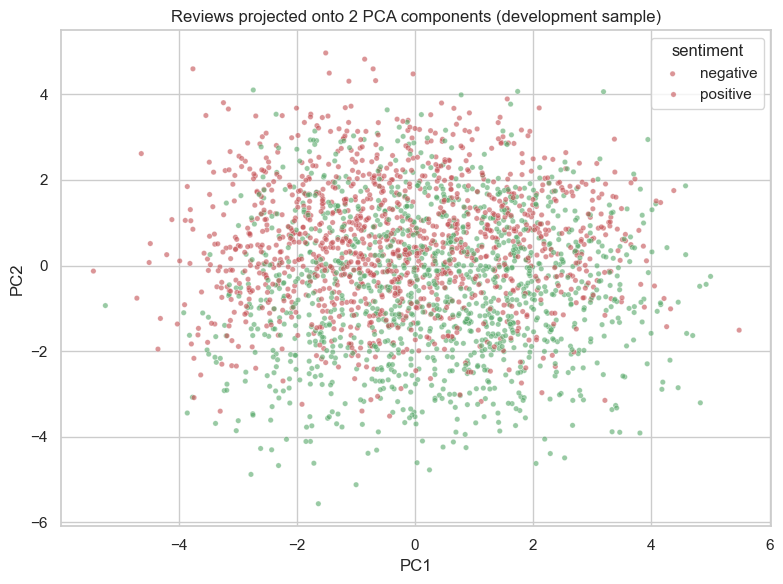

In [4]:
def to_dense(X):
    return X.toarray()

pca_steps = [
    ("tfidf", TfidfVectorizer(max_features=300, min_df=3)),
    ("scale", StandardScaler(with_mean=False)),
    ("dense", FunctionTransformer(to_dense, accept_sparse=True)),
    ("pca", PCA(n_components=2, random_state=SEED)),
]
pca_pipe = Pipeline(pca_steps)
X_dev_pca = pca_pipe.fit_transform(dev["clean_text"])
print("variance explained by 2 components:",
      round(pca_pipe.named_steps["pca"].explained_variance_ratio_.sum(), 4))

idx = np.random.RandomState(SEED).choice(len(X_dev_pca), size=min(2500, len(X_dev_pca)), replace=False)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_dev_pca[idx, 0], y=X_dev_pca[idx, 1], hue=y_dev.values[idx],
                palette=["#C44E52", "#55A868"], alpha=0.6, s=15)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Reviews projected onto 2 PCA components (development sample)")
plt.legend(title="sentiment", labels=["negative", "positive"])
plt.tight_layout()
plt.savefig(FIG_DIR / "dt_pca_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Decision Tree varieties (5-fold CV on the development subset)

| Variety | Features | Tree |
|---|---|---|
| V1 (original) | TF-IDF 300 → PCA 2 | Gini, max_depth=8, min_samples_leaf=100 |
| V2 | TF-IDF 5,000 unigrams | Gini, unpruned |
| V3 | TF-IDF 5,000 unigrams | Gini, max_depth=30 |
| V4 | TF-IDF 20,000 unigrams + bigrams | Gini, max_depth=30 |

In [5]:
def tree(**kw):
    return DecisionTreeClassifier(random_state=SEED, **kw)

varieties = {
    "V1: PCA-2, depth 8 (original)": Pipeline(pca_steps + [("dt", tree(max_depth=8, min_samples_leaf=100))]),
    "V2: TF-IDF 5k, unpruned": Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("dt", tree())]),
    "V3: TF-IDF 5k, depth 30": Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("dt", tree(max_depth=30))]),
    "V4: TF-IDF 20k (1,2), depth 30": Pipeline([("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2))),
                                                 ("dt", tree(max_depth=30))]),
}

variant_rows = []
for name, pipe in varieties.items():
    start = time.time()
    s = cross_validate(pipe, dev["clean_text"], y_dev, cv=CV, scoring=["accuracy", "f1"],
                       return_train_score=True, n_jobs=-1)
    variant_rows.append({"variety": name,
                         "train_accuracy": round(float(s["train_accuracy"].mean()), 4),
                         "cv_accuracy": round(float(s["test_accuracy"].mean()), 4),
                         "cv_f1": round(float(s["test_f1"].mean()), 4),
                         "cv_std": round(float(s["test_f1"].std()), 4),
                         "time_s": round(time.time() - start, 1)})
    print(f"{name}: CV F1 = {variant_rows[-1]['cv_f1']}  ({variant_rows[-1]['time_s']} s)")

variants_df = pd.DataFrame(variant_rows)
variants_df

V1: PCA-2, depth 8 (original): CV F1 = 0.6301  (7.0 s)
V2: TF-IDF 5k, unpruned: CV F1 = 0.7328  (40.3 s)
V3: TF-IDF 5k, depth 30: CV F1 = 0.7512  (23.5 s)
V4: TF-IDF 20k (1,2), depth 30: CV F1 = 0.7609  (45.0 s)


,variety,train_accuracy,cv_accuracy,cv_f1,cv_std,time_s
0,"V1: PCA-2, depth 8 (original)",0.6563,0.6440,0.6301,0.0054,7.0
1,"V2: TF-IDF 5k, unpruned",1.0000,0.7321,0.7328,0.0042,40.3
2,"V3: TF-IDF 5k, depth 30",0.9057,0.7462,0.7512,0.0052,23.5
3,"V4: TF-IDF 20k (1,2), depth 30",0.8996,0.7560,0.7609,0.0082,45.0


**Observations (section 3)**

- The original approach (V1, 2 PCA components) gives a CV F1 of only 0.6301. The 2 components explain just 2.11 % of the variance, so most of the information is lost, and even the train accuracy is low (0.6563), so the tree under-fits.
- Using the TF-IDF features directly (V2) raises the CV F1 to 0.7328 (+10.27 points), but the unpruned tree has a train accuracy of 1.0, so it over-fits.
- Limiting the depth to 30 helps (V3: 0.7512), and using 20,000 features with bigrams (V4) gives the best result, 0.7609, which is 13.08 points above the original approach.

## 4. Hyperparameter tuning

GridSearchCV tunes the split criterion, maximum depth and minimum samples per leaf on TF-IDF 20,000 unigram + bigram features (18 combinations, 5-fold CV, F1).

In [6]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2))),
    ("dt", tree()),
])
param_grid = {
    "dt__criterion": ["gini", "entropy"],
    "dt__max_depth": [20, 40, 80],
    "dt__min_samples_leaf": [1, 10, 50],
}
grid = GridSearchCV(pipe, param_grid, cv=CV, scoring="f1", n_jobs=-1,
                    verbose=1, return_train_score=True)
start = time.time()
grid.fit(dev["clean_text"], y_dev)
print(f"time: {(time.time() - start) / 60:.1f} min")
print("best params:", grid.best_params_)
print(f"best CV F1: {grid.best_score_:.4f}")

cv_table = pd.DataFrame(grid.cv_results_)[[
    "param_dt__criterion", "param_dt__max_depth", "param_dt__min_samples_leaf",
    "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score")
cv_table.round(4)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
time: 7.2 min
best params: {'dt__criterion': 'entropy', 'dt__max_depth': 40, 'dt__min_samples_leaf': 50}
best CV F1: 0.7611


,param_dt__criterion,param_dt__max_depth,param_dt__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
14,entropy,40,50,0.7986,0.7611,0.0066,1
5,gini,40,50,0.7953,0.7599,0.0075,2
17,entropy,80,50,0.8032,0.7588,0.0041,3
3,gini,40,1,0.9391,0.7585,0.0038,4
8,gini,80,50,0.7967,0.7557,0.0060,5
4,gini,40,10,0.8551,0.7538,0.0027,6
6,gini,80,1,0.9881,0.7490,0.0049,7
12,entropy,40,1,0.9254,0.7471,0.0073,8
7,gini,80,10,0.8686,0.7459,0.0031,9
15,entropy,80,1,0.9880,0.7452,0.0053,10


**Observations (section 4)**

- The best setting is entropy, max_depth = 40 and min_samples_leaf = 50, with a CV F1 of 0.7611 (std 0.0066), almost the same as V4 (0.7609).
- min_samples_leaf = 50 is the most useful setting: the top three results all use it. It keeps the train score (0.7986) close to the CV score, so the tree over-fits less. With min_samples_leaf = 1 and depth 80 the train score is 0.988 but the CV score is only 0.749.
- max_depth = 20 is too shallow: every depth-20 setting scored 0.7417 or lower.
- Gini and entropy give very similar results (0.7599 vs 0.7611 for depth 40 and leaf 50).

## 5. Final model and test evaluation
The best configuration is trained on the full training set (239,986 reviews). The test set is used only here, once.

training time: 273.4 s | depth: 40 | leaves: 2591
Train accuracy: 0.8060
Accuracy : 0.7791
Precision: 0.7601
Recall   : 0.8158
F1 Score : 0.7870
ROC AUC  : 0.8653

              precision    recall  f1-score   support

    Negative     0.8011    0.7423    0.7706     29986
    Positive     0.7601    0.8158    0.7870     30011

    accuracy                         0.7791     59997
   macro avg     0.7806    0.7791    0.7788     59997
weighted avg     0.7806    0.7791    0.7788     59997

Confusion matrix:
 [[22260  7726]
 [ 5528 24483]]


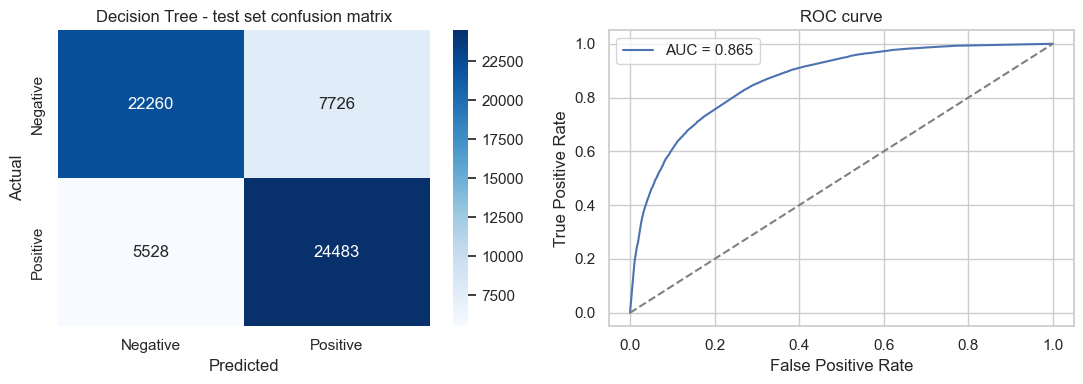

In [7]:
from sklearn.base import clone
final_model = clone(grid.best_estimator_)
start = time.time()
final_model.fit(train_df["clean_text"], y_train)
dt_train_time = round(time.time() - start, 1)
dt_fit = final_model.named_steps["dt"]
print(f"training time: {dt_train_time} s | depth: {dt_fit.get_depth()} | leaves: {dt_fit.get_n_leaves()}")

y_pred = final_model.predict(test_df["clean_text"])
y_prob = final_model.predict_proba(test_df["clean_text"])[:, 1]

acc, prec = accuracy_score(y_test, y_pred), precision_score(y_test, y_pred)
rec, f1 = recall_score(y_test, y_pred), f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
train_acc = accuracy_score(y_train, final_model.predict(train_df["clean_text"]))
print(f"Train accuracy: {train_acc:.4f}")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {auc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title("Decision Tree - test set confusion matrix")
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "dt_confusion_matrix_roc.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations (section 5)**

- The final tree has a depth of 40 and 2,591 leaves, and took 273.4 s to train on the full training set.
- The train accuracy (0.8060) is close to the test accuracy (0.7791), so the pruning settings control over-fitting.
- On the test set the tree reaches accuracy 0.7791, precision 0.7601, recall 0.8158, F1 0.7870 and ROC-AUC 0.8653.
- There are 13,254 errors (22.09 %): 7,726 negative reviews predicted as positive and 5,528 positive reviews predicted as negative. The tree favours the positive class (recall 0.8158 for positive vs 0.7423 for negative).
- The test F1 is 2.59 points above the CV F1 (0.7611), because the final tree was trained on 239,986 reviews instead of about 40,000 per CV fold.

## 6. Model interpretation
Feature importance shows which words the tree uses most, and the top three levels of the tree show its first decisions.

      feature  importance
        great      0.1313
          not      0.1239
        waste      0.0689
         best      0.0380
    excellent      0.0360
         love      0.0329
        worst      0.0320
         poor      0.0275
          but      0.0232
         good      0.0218
          bad      0.0214
 disappointed      0.0200
          and      0.0160
       boring      0.0158
         easy      0.0150
    wonderful      0.0144
disappointing      0.0111
      at best      0.0106
       highly      0.0104
           no      0.0103


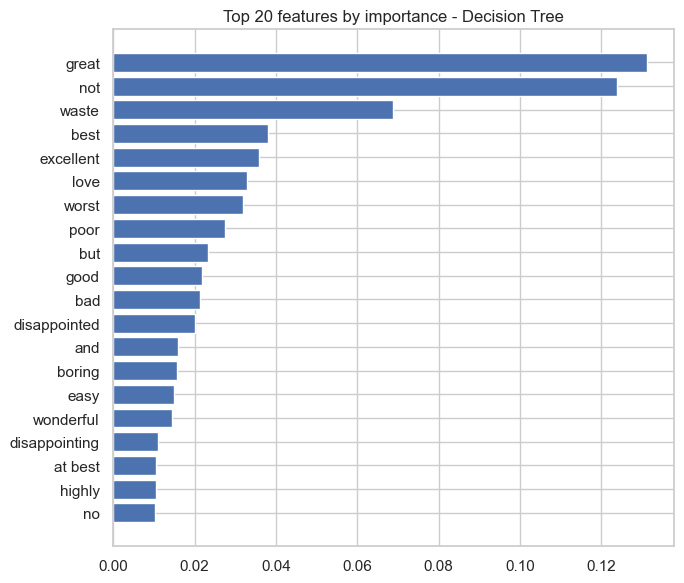

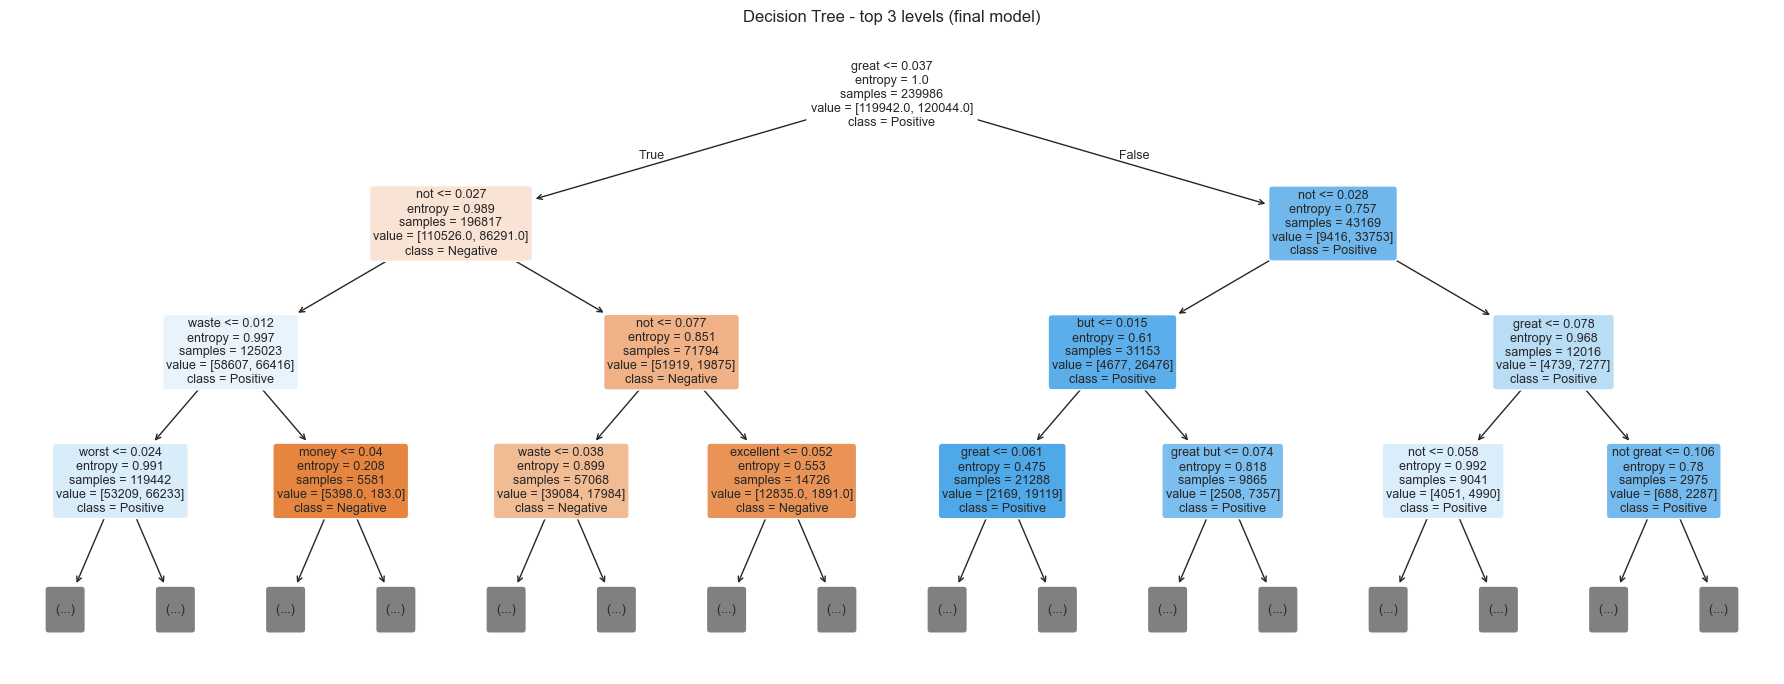


Total errors: 13254 of 59997

Error rate by review length:
                 mean   sum  count
length_bucket                     
short          0.1848  3728  20171
medium         0.2200  4411  20048
long           0.2586  5115  19778


In [8]:
names = np.array(final_model.named_steps["tfidf"].get_feature_names_out())
imp = dt_fit.feature_importances_
top = np.argsort(imp)[::-1][:20]
top_df = pd.DataFrame({"feature": names[top], "importance": imp[top]})
print(top_df.round(4).to_string(index=False))

plt.figure(figsize=(7, 6))
plt.barh(top_df["feature"][::-1], top_df["importance"][::-1], color="#4C72B0")
plt.title("Top 20 features by importance - Decision Tree")
plt.tight_layout()
plt.savefig(FIG_DIR / "dt_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(18, 7))
plot_tree(dt_fit, max_depth=3, feature_names=names, class_names=["Negative", "Positive"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree - top 3 levels (final model)")
plt.tight_layout()
plt.savefig(FIG_DIR / "dt_tree_structure.png", dpi=150, bbox_inches="tight")
plt.show()

err = pd.DataFrame({"true": y_test.values, "pred": y_pred, "word_count": test_df["word_count"].values})
err["wrong"] = err["true"] != err["pred"]
err["length_bucket"] = pd.qcut(err["word_count"], q=3, labels=["short", "medium", "long"])
print("\nTotal errors:", err["wrong"].sum(), "of", len(err))
print("\nError rate by review length:")
print(err.groupby("length_bucket", observed=True)["wrong"].agg(["mean", "sum", "count"]).round(4))

**Observations (section 6)**

- The most important features are "great" (0.131) and "not" (0.124), followed by "waste", "best", "excellent", "love", "worst" and "poor".
- Some neutral words such as "but" and "and" also get importance. The tree uses them to split mixed reviews, which suggests it is fitting details of the training data.
- The error rate increases with review length: 18.48 % for short, 22.00 % for medium and 25.86 % for long reviews.

## 7. Summary of results and saving

In [9]:
rows = [{"model_variant": r["variety"], "validation": "5-fold CV (50k dev subset)",
         "accuracy": r["cv_accuracy"], "f1": r["cv_f1"], "roc_auc": None}
        for _, r in variants_df.iterrows()]
rows.append({"model_variant": f"Tuned (GridSearchCV): {grid.best_params_}",
             "validation": "5-fold CV (50k dev subset)",
             "accuracy": None, "f1": round(grid.best_score_, 4), "roc_auc": None})
rows.append({"model_variant": "FINAL: tuned Decision Tree on full training set",
             "validation": f"Held-out test set ({len(test_df):,} reviews)",
             "accuracy": round(acc, 4), "f1": round(f1, 4), "roc_auc": round(auc, 4)})
summary = pd.DataFrame(rows)
summary.to_csv(OUT_DIR / "dt_model_summary.csv", index=False)
cv_table.to_csv(OUT_DIR / "dt_gridsearch_results.csv", index=False)
variants_df.to_csv(OUT_DIR / "dt_varieties_cv.csv", index=False)
joblib.dump(final_model, OUT_DIR / "dt_final_model.joblib")
print("Saved:", OUT_DIR / "dt_model_summary.csv")

# save the final result for the group comparison (same format in all six notebooks)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
result = {
    "model": "Decision Tree", "student_id": STUDENT_ID,
    "accuracy": round(accuracy_score(y_test, y_pred), 4),
    "precision": round(precision_score(y_test, y_pred), 4),
    "recall": round(recall_score(y_test, y_pred), 4),
    "f1": round(f1_score(y_test, y_pred), 4),
    "f1_macro": round(f1_score(y_test, y_pred, average="macro"), 4),
    "roc_auc": round(roc_auc_score(y_test, y_prob), 4),
    "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    "cv_f1_mean": round(grid.best_score_, 4),
    "cv_f1_std": round(grid.cv_results_["std_test_score"][grid.best_index_], 4),
    "train_time_s": dt_train_time, "n_train": len(train_df),
    "best_params": str(grid.best_params_), "notes": "Tuned on 50k dev subset with 5-fold CV",
}
pd.DataFrame([result]).to_csv(os.path.join(METRICS_DIR, "Decision_Tree.csv"), index=False)
print("Saved:", os.path.join(METRICS_DIR, "Decision_Tree.csv"))

pd.set_option("display.max_colwidth", 90)
summary

Saved: ..\results\outputs\dt_model_summary.csv
Saved: ..\results\final_metrics\Decision_Tree.csv


,model_variant,validation,accuracy,f1,roc_auc
0,"V1: PCA-2, depth 8 (original)",5-fold CV (50k dev subset),0.6440,0.6301,NaN
1,"V2: TF-IDF 5k, unpruned",5-fold CV (50k dev subset),0.7321,0.7328,NaN
2,"V3: TF-IDF 5k, depth 30",5-fold CV (50k dev subset),0.7462,0.7512,NaN
3,"V4: TF-IDF 20k (1,2), depth 30",5-fold CV (50k dev subset),0.7560,0.7609,NaN
4,"Tuned (GridSearchCV): {'dt__criterion': 'entropy', 'dt__max_depth': 40, 'dt__min_sampl...",5-fold CV (50k dev subset),NaN,0.7611,NaN
5,FINAL: tuned Decision Tree on full training set,"Held-out test set (59,997 reviews)",0.7791,0.7870,0.8653


## 8. Conclusion

A Decision Tree was trained on the shared sample (239,986 training and 59,997 test reviews).

- The original approach (2 PCA components) reached a CV F1 of only 0.6301. Training on the TF-IDF features directly with a depth limit and bigrams raised it to 0.7609, and tuning gave 0.7611.
- On the test set the tuned tree scored accuracy 0.7791, F1 0.7870 and ROC-AUC 0.8653.

**Limitations:** this is the lowest result in the group (14.40 points below the Linear SVM in F1: 0.7870 vs 0.9310). A single tree splits on one word at a time, so it needs very many splits to use 20,000 sparse features, it has high variance, and it predicts the positive class too often.